Task 1: Import Libraries and Verify Environment.

In [50]:
import sys
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("Python executable:", sys.executable)
print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

Python executable: c:\Users\ASAA\Desktop\dip-lab-02\.venv\Scripts\python.exe
OpenCV version: 5.0.0
NumPy version: 2.5.4
Matplotlib version: 3.11.2


Task 2: Load the Image

In [51]:
image = cv.imread("my_image.jpg")

if image is None:
    raise FileNotFoundError("Image not found. Check the filename.")

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image shape: (300, 300, 3)
Image data type: uint8


Task 3: Inspect the Image

In [52]:
height, width, channels = image.shape

print("Height:", height)
print("Width:", width)
print("Channels:", channels)

print("Top-left pixel (BGR):", image[0, 0])
print("Center pixel (BGR):", image[height // 2, width // 2])

print("Global minimum:", image.min())
print("Global maximum:", image.max())

print("Blue min/max:", image[:, :, 0].min(), image[:, :, 0].max())
print("Green min/max:", image[:, :, 1].min(), image[:, :, 1].max())
print("Red min/max:", image[:, :, 2].min(), image[:, :, 2].max())

Height: 300
Width: 300
Channels: 3
Top-left pixel (BGR): [206 150  91]
Center pixel (BGR): [122 127 136]
Global minimum: 0
Global maximum: 255
Blue min/max: 0 255
Green min/max: 0 255
Red min/max: 0 255


Task 4: Color Conversion and Channels

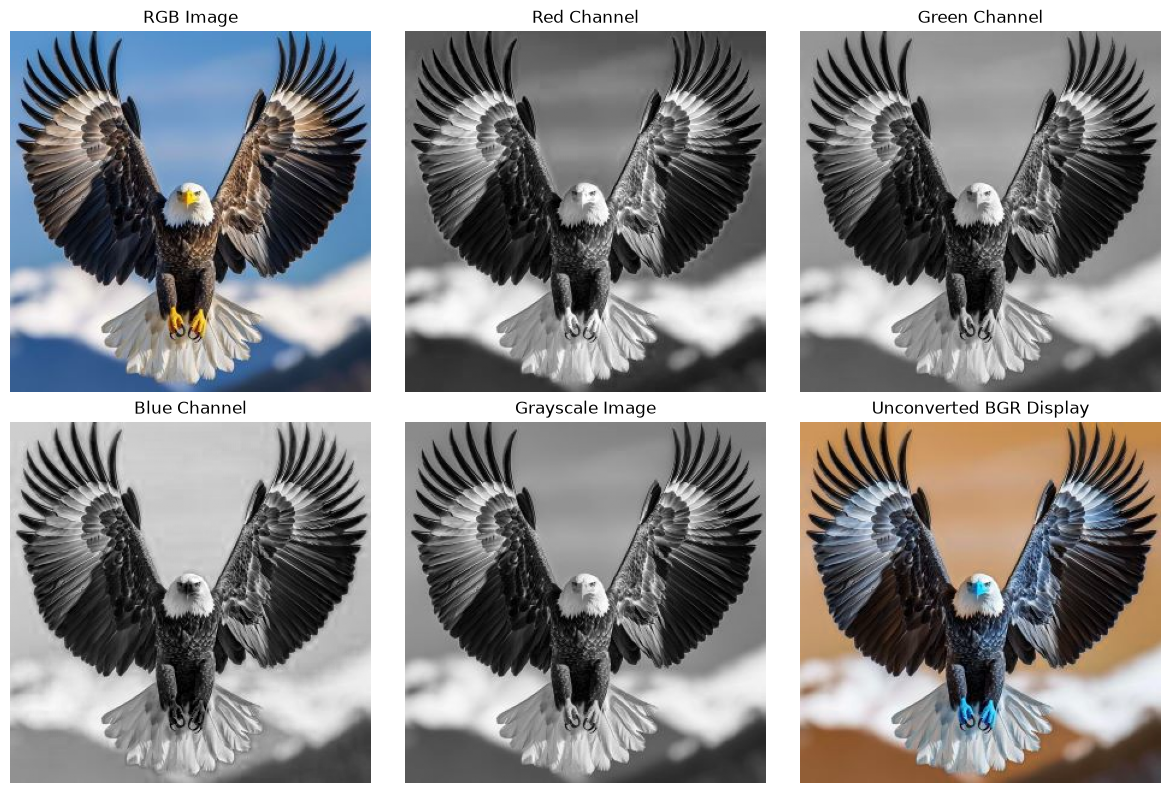

Center pixel (RGB): [136 127 122]
Center pixel HEX: #887F7A


In [53]:
rgb_image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes[0, 0].imshow(rgb_image)
axes[0, 0].set_title("RGB Image")

axes[0, 1].imshow(red_channel, cmap="gray")
axes[0, 1].set_title("Red Channel")

axes[0, 2].imshow(green_channel, cmap="gray")
axes[0, 2].set_title("Green Channel")

axes[1, 0].imshow(blue_channel, cmap="gray")
axes[1, 0].set_title("Blue Channel")

axes[1, 1].imshow(gray_image, cmap="gray")
axes[1, 1].set_title("Grayscale Image")

axes[1, 2].imshow(image)
axes[1, 2].set_title("Unconverted BGR Display")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

center_rgb = rgb_image[height // 2, width // 2]
hex_color = "#{:02X}{:02X}{:02X}".format(*center_rgb)

print("Center pixel (RGB):", center_rgb)
print("Center pixel HEX:", hex_color)

Task 5: Crop, Resize, and Save

Crop shape: (100, 100, 3)


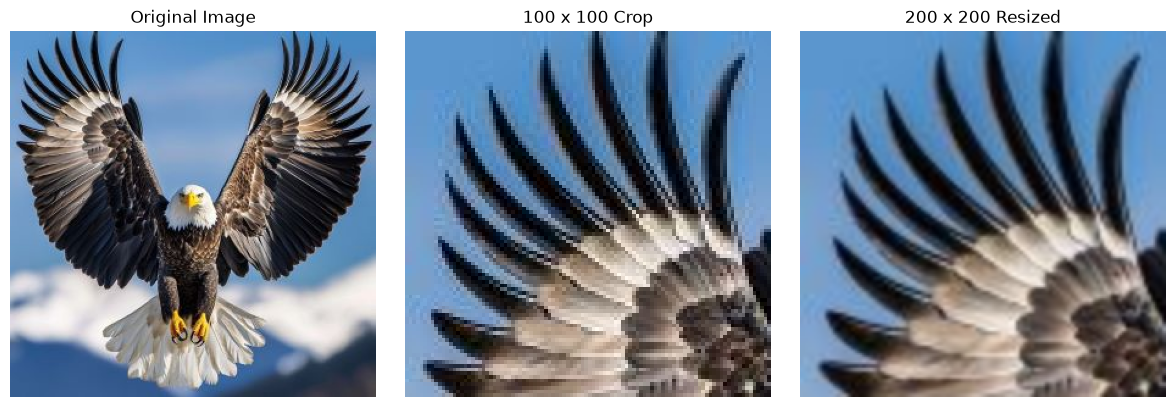

Image saved successfully: True


In [54]:
crop = image[0:100, 0:100]

print("Crop shape:", crop.shape)

crop_rgb = cv.cvtColor(crop, cv.COLOR_BGR2RGB)
resized_rgb = cv.resize(crop_rgb, (200, 200))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(rgb_image)
axes[0].set_title("Original Image")

axes[1].imshow(crop_rgb)
axes[1].set_title("100 x 100 Crop")

axes[2].imshow(resized_rgb)
axes[2].set_title("200 x 200 Resized")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

resized_bgr = cv.cvtColor(resized_rgb, cv.COLOR_RGB2BGR)
saved = cv.imwrite("resized_crop.png", resized_bgr)

print("Image saved successfully:", saved)

Task 6: Grayscale Histogram

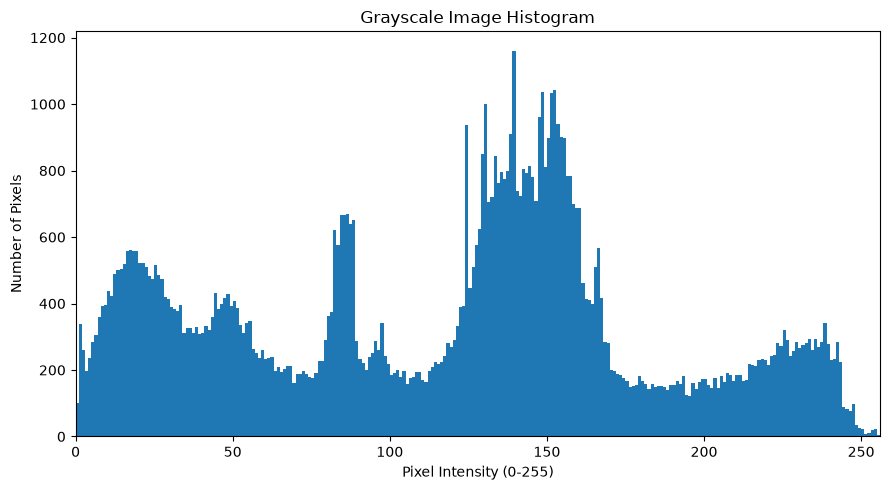

Mean grayscale intensity: 116.10138888888889
Minimum intensity: 0
Maximum intensity: 255
Histogram saved successfully.


In [55]:
gray_flat = gray_image.flatten()

plt.figure(figsize=(9, 5))
plt.hist(gray_flat, bins=256, range=(0, 256))
plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")
plt.xlim(0, 256)
plt.tight_layout()

plt.savefig("grayscale_histogram.png")
plt.show()

print("Mean grayscale intensity:", gray_image.mean())
print("Minimum intensity:", gray_image.min())
print("Maximum intensity:", gray_image.max())
print("Histogram saved successfully.")

Task 7: Bit Depth Demonstration.

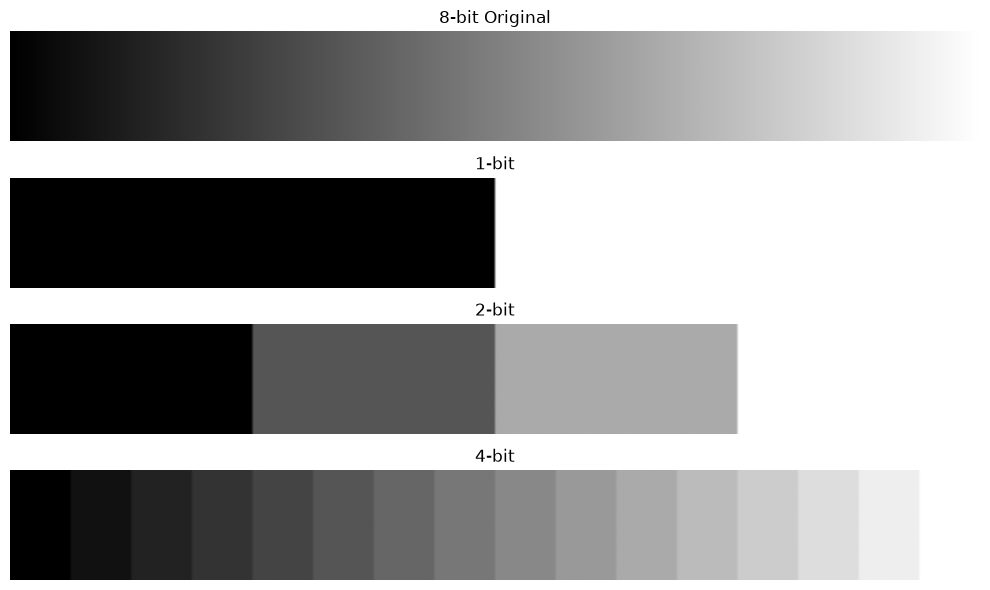

8-bit unique values: 256
1-bit unique values: 2
2-bit unique values: 4
4-bit unique values: 16


In [56]:
gradient = np.tile(
    np.arange(256, dtype=np.uint8),
    (50, 1)
)

gradient_1bit = (gradient // 128) * 255
gradient_2bit = (gradient // 64) * 85
gradient_4bit = (gradient // 16) * 17

gradients = [
    ("8-bit Original", gradient),
    ("1-bit", gradient_1bit),
    ("2-bit", gradient_2bit),
    ("4-bit", gradient_4bit)
]

fig, axes = plt.subplots(4, 1, figsize=(10, 6))

for ax, (title, grad) in zip(axes, gradients):
    ax.imshow(grad, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("8-bit unique values:", len(np.unique(gradient)))
print("1-bit unique values:", len(np.unique(gradient_1bit)))
print("2-bit unique values:", len(np.unique(gradient_2bit)))
print("4-bit unique values:", len(np.unique(gradient_4bit)))